<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 10 · Quantum transport III: superconducting junctions, LDOS, wavefunctions and currents

BdG: $H_{BdG}=\begin{pmatrix}H-\mu&\Delta\\\Delta^\dagger&-(H-\mu)^*\end{pmatrix}$; NS conductance (BTK):
$G = N_e - R_{ee} + R_{he}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import transport as tr
from hopforge import kpm

## 1. Andreev reflection at an NS junction

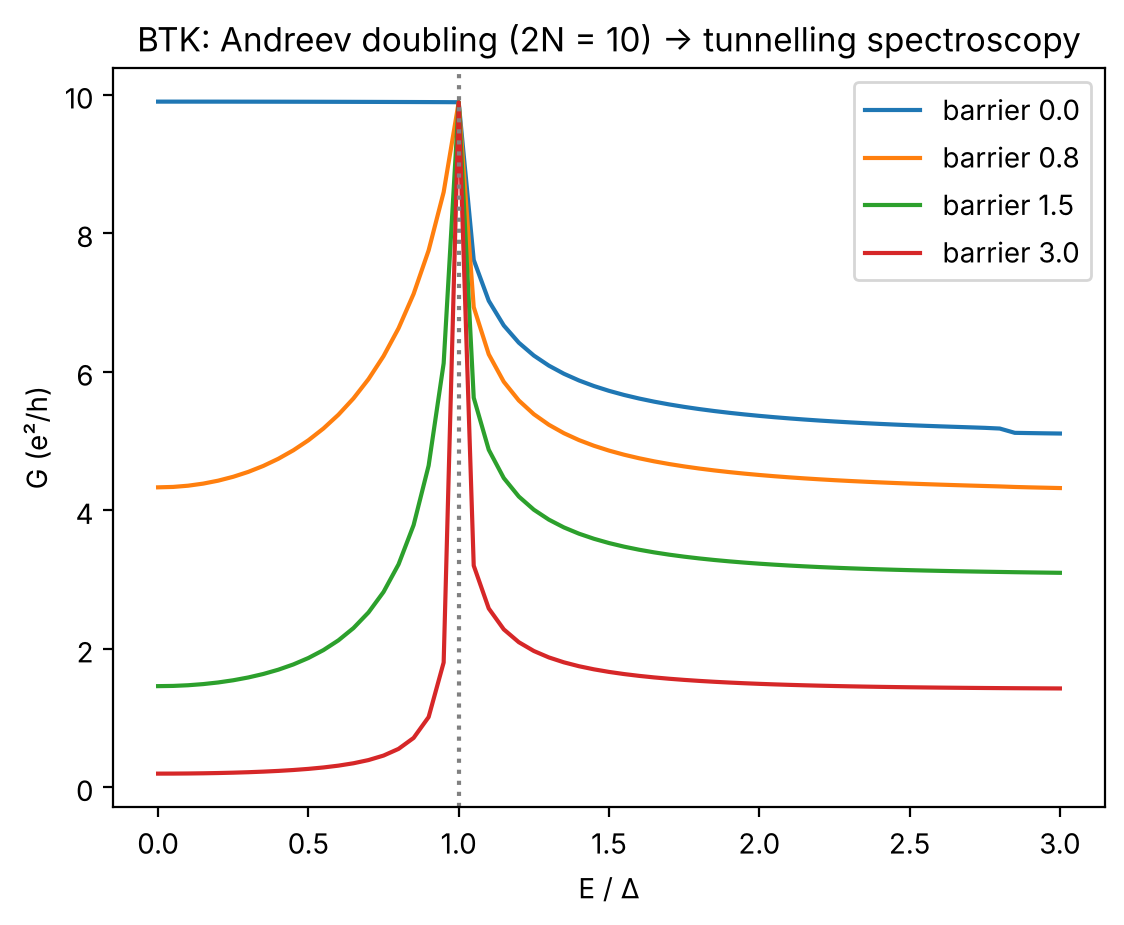

In [2]:
mu, Delta = -2.0, 0.1
Nm = M.bdg(M.square(), mu=mu, delta=0.0)        # normal region / lead
Sm = M.bdg(M.square(), mu=mu, delta=Delta)      # superconducting lead
el, ho = dict(orbitals=["A_e"]), dict(orbitals=["A_h"])
def ns_junction(barrier):
    # tunnel barrier on the last column, right at the NS interface
    pot = lambda r, name: (barrier if r[0] >= 5 else 0.0) * (1 if name.endswith("_e") else -1)
    s = tr.System(Nm, lambda r: 0 <= r[0] < 6 and 0 <= r[1] < 10, onsite=pot)
    s.attach_lead((-1, 0)); s.attach_lead((1, 0), model=Sm)
    return s
Es = np.linspace(0, 0.3, 61)
for b in (0.0, 0.8, 1.5, 3.0):
    plt.plot(Es/Delta, tr.andreev_conductance(ns_junction(b), Es, 0, el, ho), label=f"barrier {b}")
plt.axvline(1, c="gray", ls=":"); plt.xlabel("E / Δ"); plt.ylabel("G (e²/h)"); plt.legend()
plt.title("BTK: Andreev doubling (2N = 10) → tunnelling spectroscopy");

In [3]:
s = ns_junction(0.0); S = s.smatrix(0.02)
print("N_e =", S.num_modes(0, el), " R_ee =", round(S.transmission(0, 0, el, el), 4),
      " R_he =", round(S.transmission(0, 0, ho, el), 4), " -> G =", round(tr.andreev_conductance(s, 0.02, 0, el, ho)[0], 4))

N_e = 5  R_ee = 0.0479  R_he = 4.9521  -> G = 9.9042


## 2. Majorana zero mode at the end of a Kitaev chain
The NS conductance through a topological Kitaev chain shows a quantised zero-bias peak of 2e²/h.

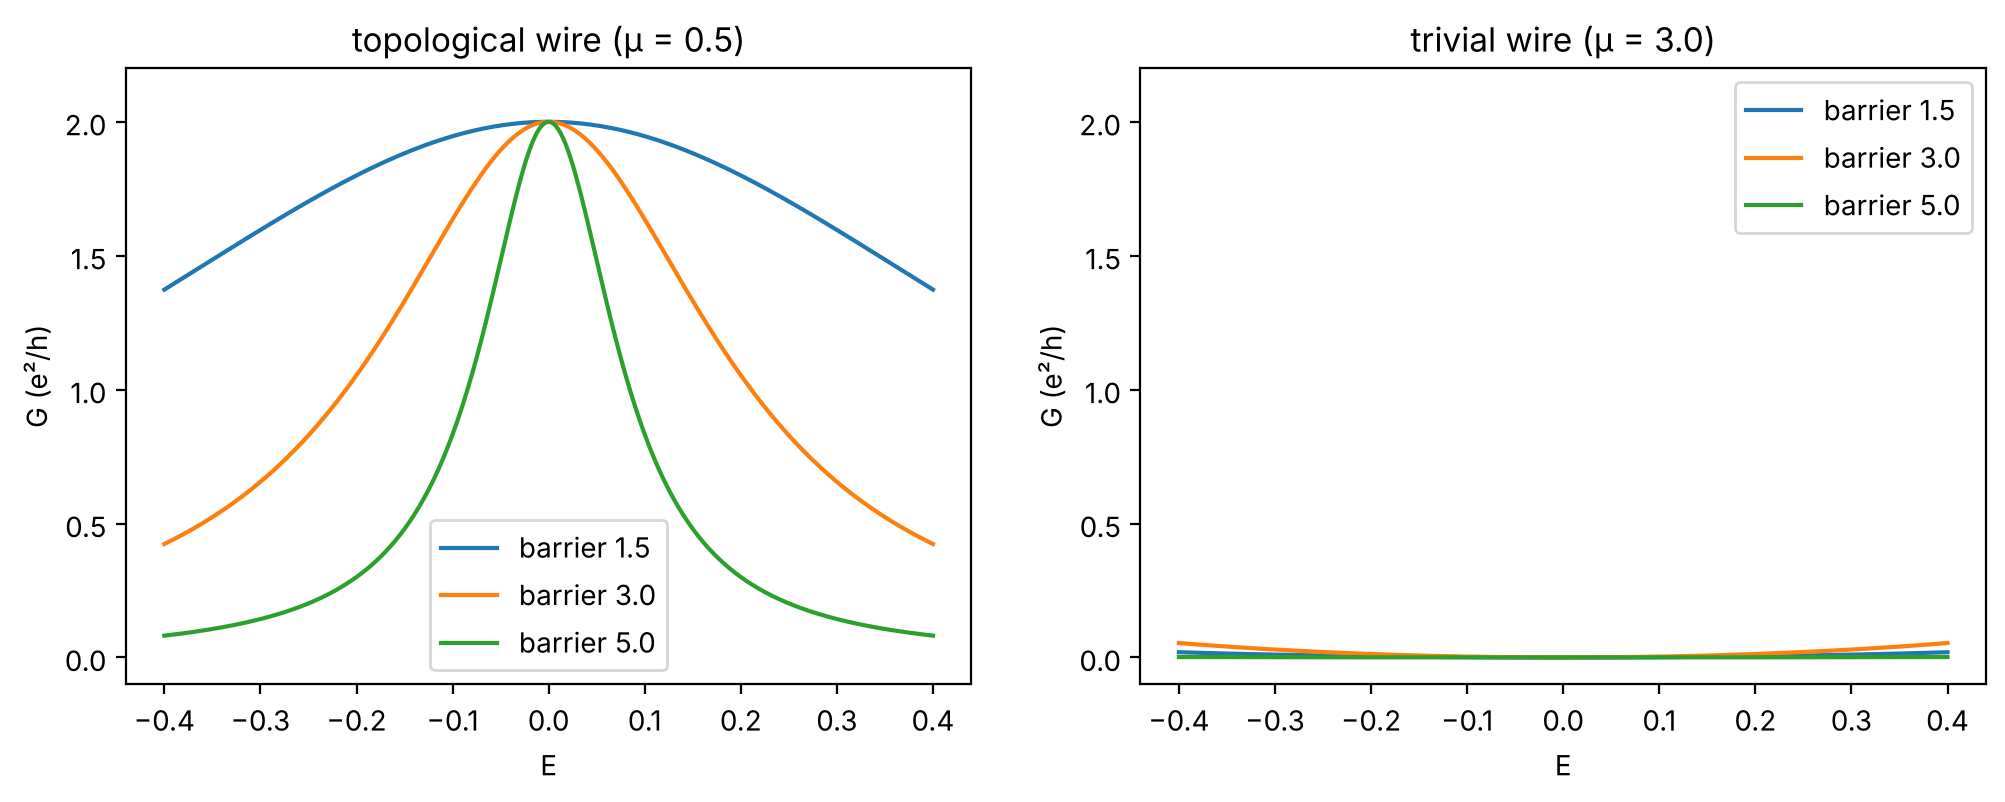

In [4]:
lead = M.kitaev_chain(mu=0.5, t=1.0, delta=0.0)          # normal metallic lead
def kitaev_device(mu_wire, Vb):
    wire = M.kitaev_chain(mu=mu_wire, t=1.0, delta=0.6)
    barrier = lambda r, name: (Vb if r[0] < 1 else 0.0) * (1 if name == "e" else -1)
    s = tr.System(wire, lambda r: 0 <= r[0] < 60, onsite=barrier)
    s.attach_lead((-1,), model=lead)
    return s
Es = np.linspace(-0.4, 0.4, 321)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, mw in zip(axes, (0.5, 3.0)):
    for Vb in (1.5, 3.0, 5.0):
        G = tr.andreev_conductance(kitaev_device(mw, Vb), Es, 0, dict(orbitals=["e"]), dict(orbitals=["h"]))
        ax.plot(Es, G, label=f"barrier {Vb}")
    ax.set_title(("topological" if mw < 2 else "trivial") + f" wire (μ = {mw})")
    ax.set_xlabel("E"); ax.set_ylabel("G (e²/h)"); ax.legend(); ax.set_ylim(-0.1, 2.2)

The topological wire shows a zero-bias peak of exactly 2e²/h (resonant Andreev reflection through the Majorana). A stronger barrier makes it narrower but not lower. The trivial wire shows no peak.

## 3. LDOS of a disordered device

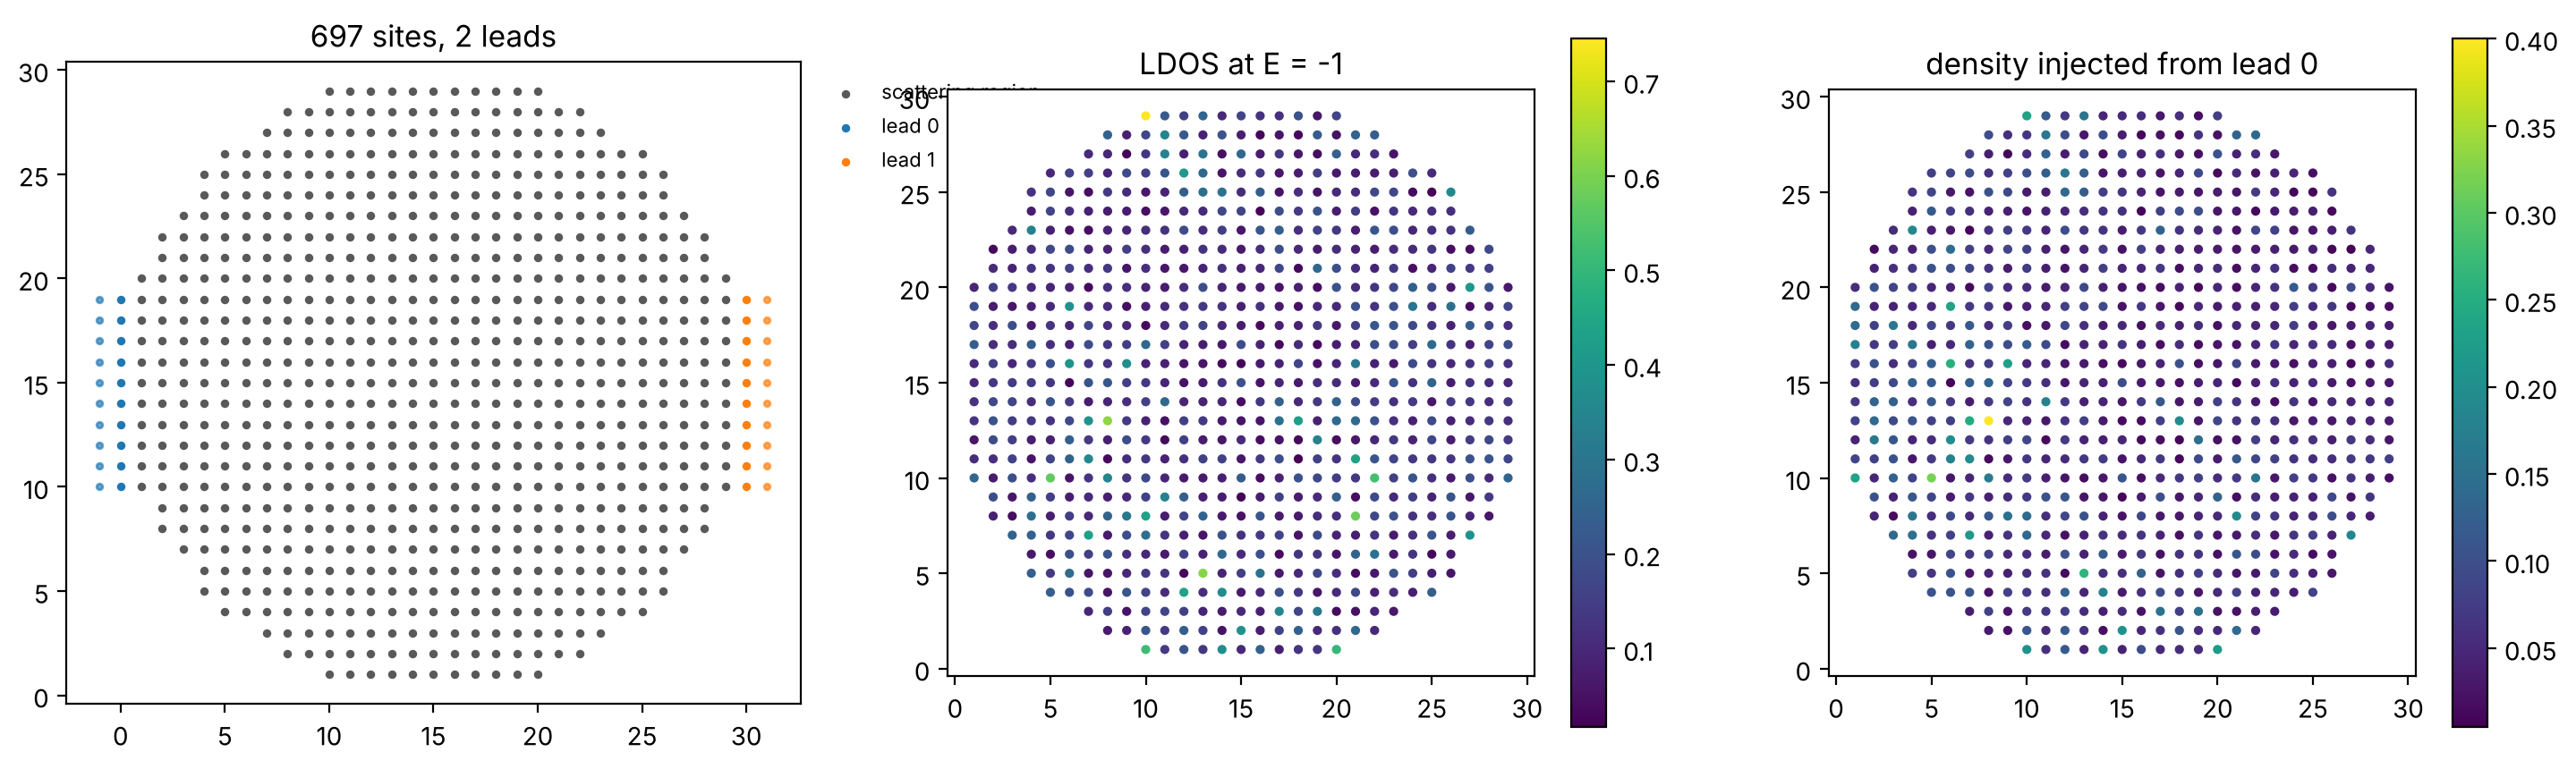

In [5]:
s = tr.System(M.square(), lambda r: (r[0]-15)**2 + (r[1]-15)**2 < 15**2, start=(15, 15),
              onsite=tr.anderson(1.5, seed=2))
s.attach_lead((-1, 0), shape=lambda r: 10 <= r[1] < 20); s.attach_lead((1, 0), shape=lambda r: 10 <= r[1] < 20)
S = s.smatrix(-1.0)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
tr.plot_system(s, ax=axes[0], bonds=False)
tr.plot_map(s, S.ldos(), ax=axes[1], title="LDOS at E = -1")
tr.plot_map(s, S.density(0), ax=axes[2], title="density injected from lead 0");

## 4. Scattering wavefunctions and currents

number of scattering states from lead 0: 7   open channels: 7


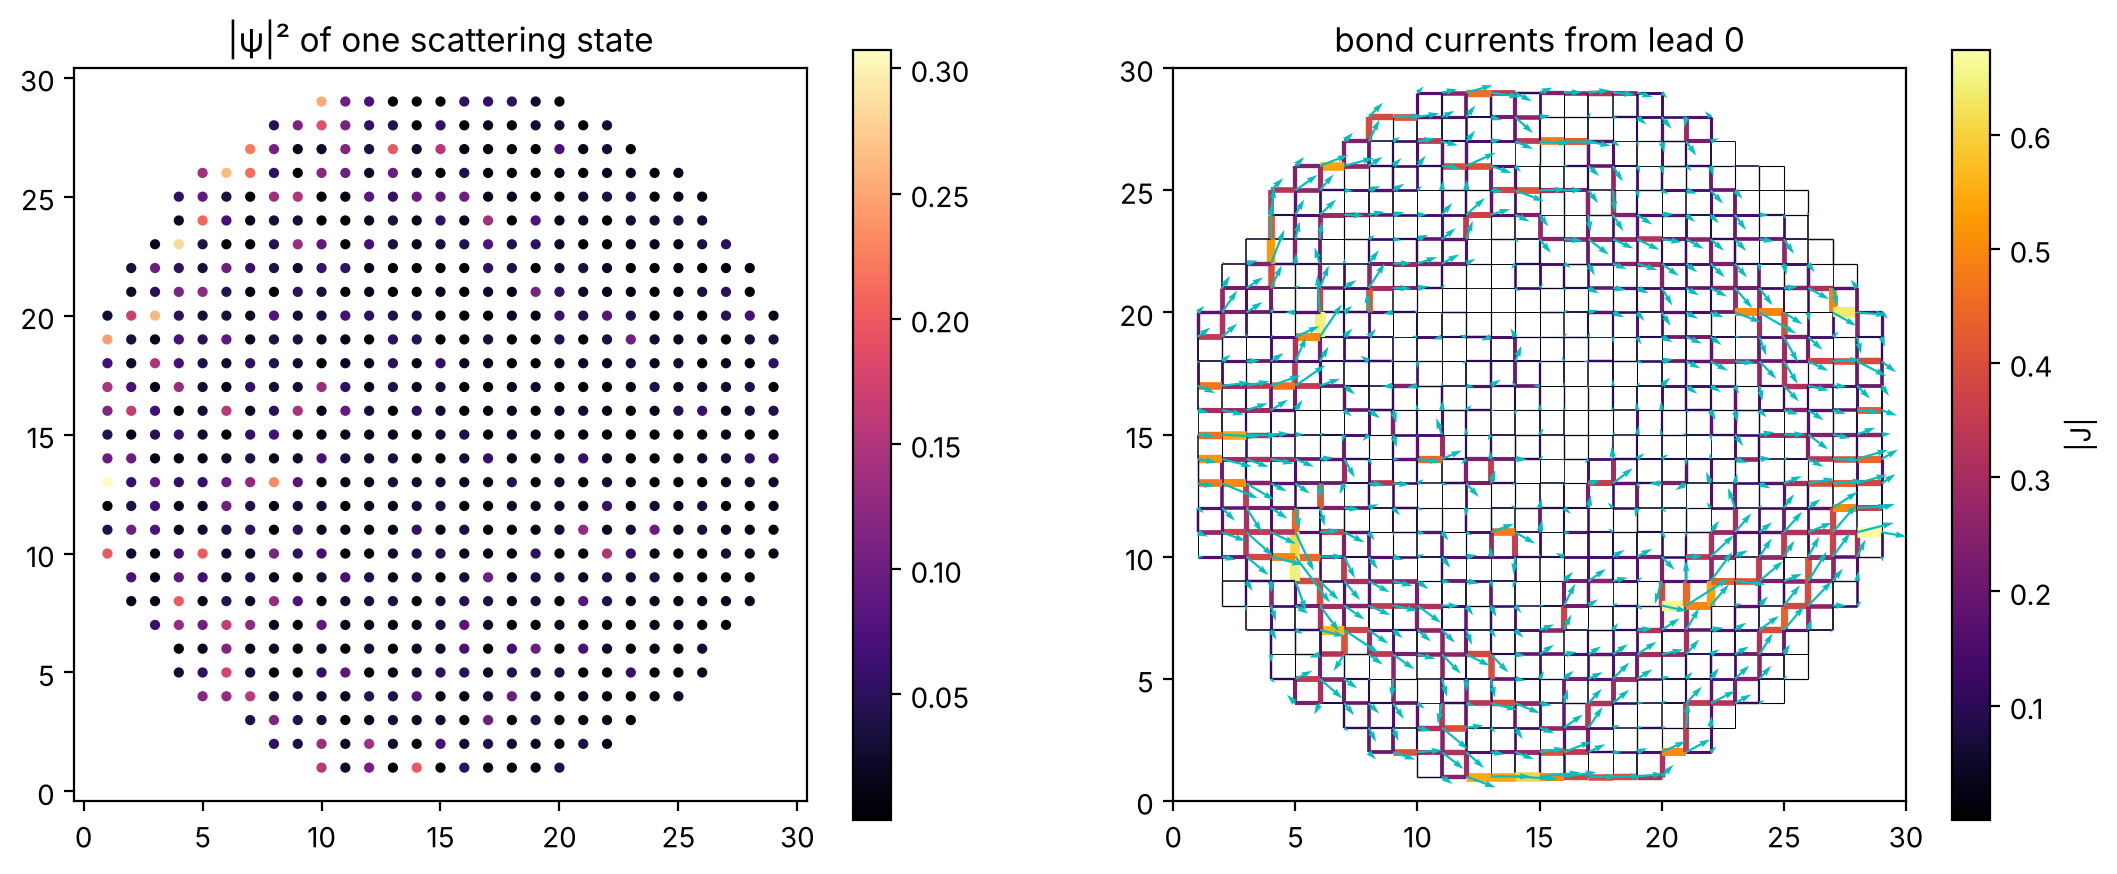

In [6]:
psi = S.wavefunctions(0)
print("number of scattering states from lead 0:", psi.shape[1], "  open channels:", S.num_modes(0))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
tr.plot_map(s, np.abs(psi[:, 0])**2, ax=axes[0], cmap="magma", title="|ψ|² of one scattering state")
b, J = S.current(0); tr.plot_current(s, b, J, ax=axes[1], title="bond currents from lead 0");

In [7]:
P = s.positions()
for xc in (8.5, 15.5, 22.5):
    cut = (P[b[:, 0], 0] - xc) * (P[b[:, 1], 0] - xc) < 0
    sign = np.sign(P[b[cut, 1], 0] - P[b[cut, 0], 0])
    print(f"current through x = {xc}: {np.sum(J[cut]*sign):.6f}   (T = {S.transmission(1, 0):.6f})")

current through x = 8.5: 3.414151   (T = 3.414151)
current through x = 15.5: 3.414151   (T = 3.414151)
current through x = 22.5: 3.414151   (T = 3.414151)


## Exercises
1. Plot the BTK conductance versus barrier height at E = 0 and compare with $2T_N^2/(2-T_N)^2$.
2. Show the Majorana peak height stays 2e²/h when the tunnel barrier is increased (it only narrows).
3. Map the LDOS of a Haldane flake connected to two leads at an energy in the bulk gap.

---
## Quiz 10: Superconductors, LDOS, wavefunctions

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [8]:
quiz = hf.Quiz(10)
quiz.interactive()

In [9]:
quiz.show()

=== Quiz 10: Superconducting junctions, LDOS, wavefunctions and currents ===

Q1. The Bogoliubov-de Gennes Hamiltonian doubles the basis into
   (a) two layers
   (b) two valleys
   (c) spin up and down
   (d) electrons and holes

Q2. `hf.models.bdg(model, mu, delta)` builds
   (a) a Hall bar
   (b) a BdG model from any normal model
   (c) a Bloch sphere
   (d) a DFT input

Q3. In Andreev reflection an electron below the gap is reflected as
   (a) a hole, transferring a Cooper pair into the superconductor
   (b) a photon
   (c) a phonon
   (d) an electron

Q4. For a transparent NS interface below the gap, G_NS equals
   (a) N/2 e^2/h
   (b) 0
   (c) N e^2/h
   (d) 2 N e^2/h

Q5. The BTK formula in hopforge is
   (a) G = R_ee
   (b) G = N_e - R_ee + R_he
   (c) G = N_e + R_ee
   (d) G = T

Q6. With a strong tunnel barrier, the subgap NS conductance
   (a) is enhanced
   (b) is 2N
   (c) is suppressed, with peaks near |E| = Delta
   (d) is unchanged

Q7. Electron/hole-resolved transmissi

In [10]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0